### Homework 04 - Measurements of rectangular tables
Igor Di Tota

In this exercise, I will study how the tolerances on the dimensions of a rectangular table propagate to quantities that depend on its dimensions.

The nominal dimensions of the table are length $L = 160$ cm and width $W = 90$ cm, with standard deviations $\sigma_L = 0.5$ cm and $\sigma_W = 0.3$ cm.
Length and width are assumed to be two independent random variables, and the table sides are always perpendicular.

The quantities we want to study are:
1.  table surface, $S = L \, W$
2.  total length of the table sides (perimeter), $P = 2(L + W)$
3.  table diagonal, $D = \sqrt{L^2 + W^2}$

For each of them the expected standard deviation will be computed, toghether with the correlation between $S$ and $P$.
Two ways will be used:
- **analytically**, using the error propagation formula;
- **numerically**, generating many tables with $L$ and $W$ drawn from Gaussian distributions.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import os
os.makedirs("images", exist_ok=True)

rng = np.random.default_rng(23)

# Nominal dimensions in cm
L = 160
W = 90

# Production tolerances in cm (standard deviations)
sigma_L = 0.5
sigma_W = 0.3

### Analytical error propagation

The input variables are $\mathbf{X} = (L, W)$.

Since length and width are independent, their covariance matrix is written in diagonal form as
$$
\mathbb{C}_X =
\begin{pmatrix}
\sigma_L^2 & 0 \\
0 & \sigma_W^2
\end{pmatrix}.
$$

The output variables are $\mathbf{Y} = (S, P, D)$, with
$$
S = L\, W, \qquad P = 2(L + W), \qquad D = \sqrt{L^2 + W^2}.
$$

To propagate the uncertainties from $\mathbf{X}$ to $\mathbf{Y}$, we use the general error propagation formula seen in the lecture:
$$
\mathbb{C}_Y = A\, \mathbb{C}_X\, A^\intercal ,
$$
where $A$ is the matrix of partial derivatives $A_{ij} = \partial y_i / \partial x_j$ for transformation to $\mathbf{Y}$, evaluated at the nominal values $L = 160$ cm and $W = 90$ cm:
$$
A =
\begin{pmatrix}
\dfrac{\partial S}{\partial L} & \dfrac{\partial S}{\partial W} \\[2ex]
\dfrac{\partial P}{\partial L} & \dfrac{\partial P}{\partial W} \\[2ex]
\dfrac{\partial D}{\partial L} & \dfrac{\partial D}{\partial W}
\end{pmatrix}
=
\begin{pmatrix}
W & L \\[1ex]
2 & 2 \\[1ex]
\dfrac{L}{D} & \dfrac{W}{D}
\end{pmatrix}.
$$

This formula comes from a first order Taylor expansion of $\mathbf{Y}(\mathbf{X})$ around the nominal values, so it is only an approximation for non-linear functions such as $S$ and $D$.
It is exact for the perimeter $P$, which is linear in $L$ and $W$.

The approximation is good when the standard deviations are small compared to the nominal values, as in our case ($\sigma_L / L \approx 0.3\%$, $\sigma_W / W \approx 0.3\%$).

The elements we are interested in are
$$
\sigma_S^2 = W^2\sigma_L^2 + L^2\sigma_W^2, \qquad
\sigma_P^2 = 4\left(\sigma_L^2 + \sigma_W^2\right), \qquad
\sigma_D^2 = \frac{L^2\sigma_L^2 + W^2\sigma_W^2}{L^2 + W^2},
$$
$$
\mathrm{Cov}(S, P) = 2\left(W\,\sigma_L^2 + L\,\sigma_W^2\right).
$$

Finally, the correlation coefficient between the surface and the total edge length is
$$
\rho(S, P) = \frac{\mathrm{Cov}(S, P)}{\sigma_S\, \sigma_P}.
$$


In [14]:
# Nominal diagonal
D = np.sqrt(L**2 + W**2)

# Covariance matrix of the input variables (L, W)
C_X = np.array([[sigma_L**2, 0],
                [0, sigma_W**2]])

# Matrix of partial derivatives, rows: S, P, D, columns: L, W
A = np.array([[W,     L    ],
              [2,     2    ],
              [L / D, W / D]])

# Covariance matrix of the output variables (S, P, D)
C_Y = A @ C_X @ A.T

print("C_Y =")
print(C_Y)


C_Y =
[[4.32900000e+03 7.38000000e+01 2.66702114e+01]
 [7.38000000e+01 1.36000000e+00 5.24034792e-01]
 [2.66702114e+01 5.24034792e-01 2.11543027e-01]]


In [15]:
# Standard deviations from the diagonal of C_Y
sigma_S, sigma_P, sigma_D = np.sqrt(np.diag(C_Y))

# Covariance and correlation between S and P
cov_SP = C_Y[0, 1]
rho_SP = cov_SP / (sigma_S * sigma_P)

print(f"S = {L * W:.1f} ± {sigma_S:.1f} cm^2    (relative: {sigma_S / (L * W) * 100:.2f}%)")
print(f"P = {2 * (L + W):.2f} ± {sigma_P:.2f} cm       (relative: {sigma_P / (2 * (L + W)) * 100:.2f}%)")
print(f"D = {D:.2f} ± {sigma_D:.2f} cm       (relative: {sigma_D / D * 100:.2f}%)")
print(f"\nCov(S, P) = {cov_SP:.2f} cm^3")
print(f"rho(S, P) = {rho_SP:.4f}")



S = 14400.0 ± 65.8 cm^2    (relative: 0.46%)
P = 500.00 ± 1.17 cm       (relative: 0.23%)
D = 183.58 ± 0.46 cm       (relative: 0.25%)

Cov(S, P) = 73.80 cm^3
rho(S, P) = 0.9618


### Comments on the results

**Surface.** The surface has the largest relative uncertainty, $0.46\%$.
As shown in the lecture, for a product of independent variables the relative uncertainties add in quadrature:
$$
\frac{\sigma_S}{S} = \sqrt{\left(\frac{\sigma_L}{L}\right)^2 + \left(\frac{\sigma_W}{W}\right)^2} = \sqrt{(0.31\%)^2 + (0.33\%)^2} \approx 0.46\% .
$$
The two contributions are comparable: $W^2\sigma_L^2 = 2025 \ \text{cm}^4$ and $L^2\sigma_W^2 = 2304 \ \text{cm}^4$.
Even if $\sigma_W$ is smaller than $\sigma_L$, the width contributes slightly more, because its fluctuation is multiplied by the longer side $L$.

**Perimeter.** For a sum it is the absolute uncertainties that add in quadrature, so $\sigma_P = 2\sqrt{\sigma_L^2 + \sigma_W^2}$.
Since $P$ is linear in $L$ and $W$, this result is exact and not an approximation.

**Diagonal.** The variance of the diagonal is dominated by the length: $L^2\sigma_L^2 = 6400 \ \text{cm}^4$ against $W^2\sigma_W^2 = 729 \ \text{cm}^4$, so about $90\%$ of $\sigma_D^2$ comes from $L$.
This is expected, since the diagonal of a long table is almost parallel to its longer side.

**Correlation.** The correlation between $S$ and $P$ is very strong and positive, $\rho(S, P) \approx 0.96$: both quantities increase when $L$ or $W$ increase, so they fluctuate together.
It is not exactly $1$ because $S$ and $P$ respond to $L$ and $W$ with different weights:
- $(W, L)$ for $S$;
- $(2, 2)$ for $P$.

### Numerical experiment

To check the analytical results, I simulate the production of a large number $N$ of tables.
For each table, the length and the width are drawn independently from Gaussian distributions:
$$
L_i \sim \mathcal{N}(L, \sigma_L^2), \qquad W_i \sim \mathcal{N}(W, \sigma_W^2), \qquad i = 1, \dots, N .
$$

For each generated table the surface $S_i$, the perimeter $P_i$ and the diagonal $D_i$ are computed.

#### Sample variance

Let $x_1, \dots, x_N$ be one of these samples, coming from a distribution with true mean $\mu$ and true variance $\sigma^2$.
The true mean $\mu$ is not known, so we estimate it with the sample mean
$$
\bar{x} = \frac{1}{N} \sum_i x_i ,
$$
with variance $\mathbb{V}(\bar{x}) = \sigma^2 / N$.

To measure the spread of the sample, for each value we take its deviation from the sample mean, $x_i - \bar{x}$, and we average the squared deviations:
$$
d^2 = \frac{1}{N} \sum_i (x_i - \bar{x})^2 .
$$

This is not an unbiased estimator of $\sigma^2$.
Writing each deviation as $x_i - \bar{x} = (x_i - \mu) - (\bar{x} - \mu)$ and expanding the square:
$$
\begin{aligned}
d^2 &= \frac{1}{N} \sum_i \left[ (x_i - \mu)^2 - 2 (x_i - \mu)(\bar{x} - \mu) + (\bar{x} - \mu)^2 \right] \\
    &= \frac{1}{N} \sum_i (x_i - \mu)^2 - 2 (\bar{x} - \mu) \underbrace{\frac{1}{N} \sum_i (x_i - \mu)}_{=\ \bar{x} - \mu} + (\bar{x} - \mu)^2 \\
    &= \frac{1}{N} \sum_i (x_i - \mu)^2 - (\bar{x} - \mu)^2 .
\end{aligned}
$$
Taking the expectation value, the first term gives $\sigma^2$ and the second one gives the variance of the sample mean:
$$
\langle d^2 \rangle = \sigma^2 - \mathbb{V}(\bar{x}) = \sigma^2 - \frac{\sigma^2}{N} = \frac{N-1}{N}\, \sigma^2 .
$$

To correct this bias we multiply by Bessel's factor $N / (N-1)$ and obtain the sample variance
$$
s^2 = \frac{N}{N-1}\, d^2 = \frac{1}{N-1} \sum_i (x_i - \bar{x})^2 , \qquad \langle s^2 \rangle = \sigma^2 .
$$

#### Sample correlation

In the same way, the correlation between $S$ and $P$ is estimated with the sample covariance and the sample correlation coefficient, given in the slide 31 of the lecture:
$$
s^2_{SP} = \frac{1}{N-1} \sum_i (S_i - \bar{S})(P_i - \bar{P}), \qquad r_{SP} = \frac{s^2_{SP}}{s_S\, s_P} ,
$$
where $s_S$ and $s_P$ are the sample standard deviations of $S$ and $P$.

In `numpy`, the sample standard deviation is computed with `x.std(ddof=1)`, which returns
$$
\sqrt{\frac{1}{N - \texttt{ddof}} \sum_i (x_i - \bar{x})^2} ,
$$
where `ddof` is subtracted from $N$ in the denominator.
The value `ddof=1` applies Bessel's correction and gives $s$.


In [16]:
N = 1000000

# Generate N tables with Gaussian length and width
L_i = rng.normal(L, sigma_L, size=N)
W_i = rng.normal(W, sigma_W, size=N)

# std(ddof=1): sample standard deviation, divides by N-1
print(f"Generated {N} tables")
print(f"Mean length: {L_i.mean():.4f} cm,  sample std: {L_i.std(ddof=1):.4f} cm")
print(f"Mean width:  {W_i.mean():.4f} cm,  sample std: {W_i.std(ddof=1):.4f} cm")

Generated 1000000 tables
Mean length: 159.9995 cm,  sample std: 0.4998 cm
Mean width:  90.0004 cm,  sample std: 0.2999 cm


In [17]:
# Derived quantities for each table
S_i = L_i * W_i
P_i = 2 * (L_i + W_i)
D_i = np.sqrt(L_i**2 + W_i**2)

# Sample standard deviations
s_S = S_i.std(ddof=1)
s_P = P_i.std(ddof=1)
s_D = D_i.std(ddof=1)

# Sample covariance and sample correlation coefficient between S and P
s2_SP = np.sum((S_i - S_i.mean()) * (P_i - P_i.mean())) / (N - 1)
r_SP = s2_SP / (s_S * s_P)

# Comparison between the analytical and the numerical results
print(f"{'':<12}{'Analytical':>12}{'Numerical':>12}{'Rel. diff.':>12}")
for name, a, n in [("sigma_S", sigma_S, s_S),
                   ("sigma_P", sigma_P, s_P),
                   ("sigma_D", sigma_D, s_D),
                   ("Cov(S, P)", cov_SP, s2_SP),
                   ("rho(S, P)", rho_SP, r_SP)]:
    print(f"{name:<12}{a:>12.4f}{n:>12.4f}{(n - a) / a * 100:>11.3f}%")


              Analytical   Numerical  Rel. diff.
sigma_S          65.7951     65.7891     -0.009%
sigma_P           1.1662      1.1660     -0.014%
sigma_D           0.4599      0.4598     -0.021%
Cov(S, P)        73.8000     73.7847     -0.021%
rho(S, P)         0.9618      0.9618      0.003%


### Visualisation of the generated tables

To visualise the effect of the production tolerances, I draw the first 10 generated tables with the bottom-left corner fixed at the origin.
Since the fluctuations are of a few millimetres on dimensions of the order of one metre, they are not visible on the full scale, so I also show a zoom on the top-right corner, in a range of $\pm 3\sigma$ around the nominal dimensions.


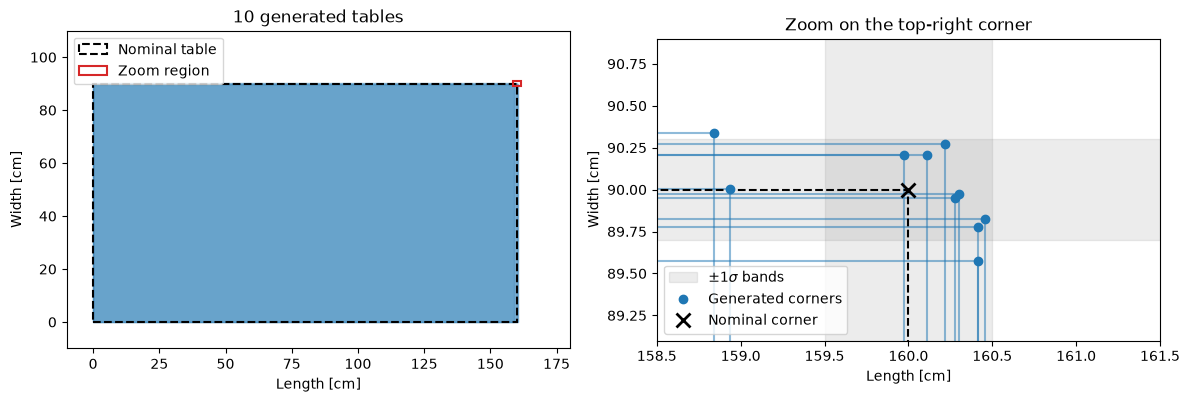

In [20]:
from matplotlib.patches import Rectangle

n_show = 10

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(12, 5))

# Full view
for k in range(n_show):
    ax_full.add_patch(Rectangle((0, 0), L_i[k], W_i[k],
                                facecolor="tab:blue", edgecolor="tab:blue", alpha=0.1))
ax_full.add_patch(Rectangle((0, 0), L, W, fill=False, edgecolor="black",
                            linestyle="--", linewidth=1.5, label="Nominal table"))
# Region shown in the zoom
ax_full.add_patch(Rectangle((L - 3 * sigma_L, W - 3 * sigma_W), 6 * sigma_L, 6 * sigma_W,
                            fill=False, edgecolor="tab:red", linewidth=1.5, label="Zoom region"))
ax_full.set_xlim(-10, L + 20)
ax_full.set_ylim(-10, W + 20)
ax_full.set_aspect("equal")
ax_full.set_xlabel("Length [cm]")
ax_full.set_ylabel("Width [cm]")
ax_full.set_title(f"{n_show} generated tables")
ax_full.legend(loc="upper left")

# Zoom on the top-right corner
ax_zoom.axvspan(L - sigma_L, L + sigma_L, color="gray", alpha=0.15, label=r"$\pm 1\sigma$ bands")
ax_zoom.axhspan(W - sigma_W, W + sigma_W, color="gray", alpha=0.15)
for k in range(n_show):
    ax_zoom.add_patch(Rectangle((0, 0), L_i[k], W_i[k], fill=False,
                                edgecolor="tab:blue", linewidth=1.5, alpha=0.5))
ax_zoom.plot(L_i[:n_show], W_i[:n_show], "o", color="tab:blue", label="Generated corners")
ax_zoom.add_patch(Rectangle((0, 0), L, W, fill=False, edgecolor="black",
                            linestyle="--", linewidth=1.5))
ax_zoom.plot(L, W, "x", color="black", markersize=10, mew=2, label="Nominal corner")
ax_zoom.set_xlim(L - 3 * sigma_L, L + 3 * sigma_L)
ax_zoom.set_ylim(W - 3 * sigma_W, W + 3 * sigma_W)
ax_zoom.set_aspect("equal")
ax_zoom.set_xlabel("Length [cm]")
ax_zoom.set_ylabel("Width [cm]")
ax_zoom.set_title("Zoom on the top-right corner")
ax_zoom.legend(loc="lower left")

plt.tight_layout()
plt.savefig("images/tables.pdf")
plt.show()
